# 08. Neural Network — Stage 0

The objective of this notebook is to evaluate a feedforward neural network
for the Stage-0 volatility-prediction problem.

The task is a binary classification problem in which the target indicates
whether future five-day realized volatility is sufficiently higher than the
current 20-day volatility.

The feature set was constructed in `05_feature_engineering_s0.ipynb` and
combines conventional statistical features with topological features derived
in `04_tda.ipynb`.

The previous notebooks established logistic regression, Random Forest, and
XGBoost as reference models. We now investigate whether a feedforward neural
network can extract additional nonlinear relationships from the same
Stage-0 feature representation.

The experiments will preserve the chronological evaluation framework used
throughout the project. The data will be divided into training
(2010--2020), validation (2021--2022), and test (2023--2026) periods.

Neural-network architecture and hyperparameters will be selected using the
training and validation data only. The test period will remain untouched
until the final evaluation.

Because neural networks are sensitive to feature scale, feature
standardization will be performed using the reusable preprocessing utilities
in `src/preprocessing.py`. The scaler will be fitted only on the training
period and subsequently applied to the validation and test periods.

The purpose of this experiment is not simply to maximize predictive
performance. It provides a Stage-0 nonlinear neural-network reference that
can later be compared with the tree-based models and with the
one-dimensional CNN developed in Stage 1.

## 1. Project Setup and Imports

### 1.1 Define Project Path

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

STAGE0_DATA_FILE = (
    PROCESSED_DATA_DIR / "spy_stage0_features.csv"
)

### 1.2: Import libraries

In [2]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

## 2. Load Stage-0 Dataset

We use the feature dataset constructed in
`05_feature_engineering_s0.ipynb`.

The dataset contains the statistical and topological features used for the
Stage-0 prediction problem together with the binary target.

No feature construction is performed in this notebook; the purpose here is
to establish the neural-network modeling experiment using the same dataset
used by the preceding Stage-0 models.

In [3]:
stage0_data = pd.read_csv(
    STAGE0_DATA_FILE,
    index_col=0,
    parse_dates=True,
)

stage0_data.head()

,log_return,abs_return,squared_return,vol_5d,vol_10d,vol_20d,vol_60d,vol_ratio_5_20,vol_ratio_20_60,abs_return_lag_1,...,h0_mean_persistence,h0_max_persistence,h1_total_persistence,h1_mean_persistence,h1_max_persistence,h1_n_features,h1_l1_norm,h1_l2_norm,h1_sup_norm,target
date,,,,,,,,,,,,,,,,,,,,,
2010-03-31,-0.003413,0.003413,0.000012,0.003322,0.004271,0.005152,0.008848,0.644720,0.582289,0.000681,...,0.003322,0.007881,0.000868,0.000868,0.000868,1,1.883799e-07,0.000007,0.000434,0
2010-04-01,0.006815,0.006815,0.000046,0.004449,0.004781,0.005330,0.008885,0.834670,0.599885,0.003413,...,0.002969,0.007881,0.000868,0.000868,0.000868,1,1.883799e-07,0.000007,0.000434,0
2010-04-05,0.008116,0.008116,0.000066,0.005735,0.005184,0.004651,0.008946,1.233187,0.519877,0.006815,...,0.002615,0.004491,0.000868,0.000868,0.000868,1,1.883799e-07,0.000007,0.000434,0
2010-04-06,0.002355,0.002355,0.000006,0.005098,0.004958,0.004680,0.008934,1.089330,0.523846,0.008116,...,0.002702,0.004491,0.000688,0.000344,0.000555,2,8.148190e-08,0.000004,0.000278,0
2010-04-07,-0.005729,0.005729,0.000033,0.005698,0.004791,0.004838,0.008955,1.177664,0.540292,0.002355,...,0.002828,0.005156,0.001775,0.000444,0.001358,4,4.757887e-07,0.000014,0.000679,1


In [4]:
# inspect it 
stage0_data.shape

(4131, 28)

In [5]:
stage0_data.index.min(), stage0_data.index.max()

(Timestamp('2010-03-31 00:00:00'), Timestamp('2026-09-01 00:00:00'))

In [6]:
# should get 0 -> 3118, 1 -> 1013
stage0_data["target"].value_counts()

target
0    3118
1    1013
Name: count, dtype: int64

## 3. Chronological Train, Validation, and Test Split

We retain the same chronological split used by the Stage-0 baseline and
tree-model experiments:

- Training: 2010--2020
- Validation: 2021--2022
- Test: 2023--2026

The chronological ordering is essential because the observations form a
financial time series. Random shuffling would allow information from later
periods to influence the training data.

The validation period will be used for neural-network architecture and
hyperparameter selection. The test period will remain untouched until the
final evaluation.

### 3.1: Define the split

In [7]:
TRAIN_END = "2020-12-31"
VALIDATION_END = "2022-12-31"

train_mask = stage0_data.index <= TRAIN_END

validation_mask = (
    (stage0_data.index > TRAIN_END)
    & (stage0_data.index <= VALIDATION_END)
)

test_mask = stage0_data.index > VALIDATION_END

### 3.2: Create the three datasets

In [8]:
train_data = stage0_data.loc[train_mask].copy()

validation_data = stage0_data.loc[
    validation_mask
].copy()

test_data = stage0_data.loc[
    test_mask
].copy()

In [9]:
print("Training:", train_data.shape)
print("Validation:", validation_data.shape)
print("Test:", test_data.shape)

Training: (2709, 28)
Validation: (503, 28)
Test: (919, 28)


### 3.3: Separate feature and target

In [10]:
FEATURE_COLUMNS = [
    column
    for column in stage0_data.columns
    if column != "target"
]

X_train = train_data[FEATURE_COLUMNS]
y_train = train_data["target"]

X_validation = validation_data[FEATURE_COLUMNS]
y_validation = validation_data["target"]

X_test = test_data[FEATURE_COLUMNS]
y_test = test_data["target"]

In [11]:
# sanity check
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_validation:", X_validation.shape)
print("y_validation:", y_validation.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (2709, 27)
y_train: (2709,)
X_validation: (503, 27)
y_validation: (503,)
X_test: (919, 27)
y_test: (919,)


## 4. Feature Standardization

Neural networks generally benefit from features being placed on comparable
scales.

We therefore standardize the 27 Stage-0 features using the reusable
`standardize_features()` function from `src/preprocessing.py`.

The scaler is fitted **only on the training data**. The same transformation
is then applied to the validation and test sets.

This prevents information from the validation or test periods from entering
the preprocessing step.

In [12]:
from src.preprocessing import standardize_features

In [13]:
# standardize the three datasets
scaler, X_train_scaled, X_validation_scaled = (
    standardize_features(
        X_train,
        X_validation,
    )
)

In [14]:
X_test_scaled = scaler.transform(X_test)

In [15]:
# verify the shapes
print("X_train_scaled:", X_train_scaled.shape)
print("X_validation_scaled:", X_validation_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)

X_train_scaled: (2709, 27)
X_validation_scaled: (503, 27)
X_test_scaled: (919, 27)


In [16]:
# verify the training scaling
print(
    "Training mean:",
    X_train_scaled.mean(),
)

print(
    "Training standard deviation:",
    X_train_scaled.std(),
)

Training mean: 2.3897503930244132e-17
Training standard deviation: 1.0


In [17]:
# this code checks whether two NumPy arrays contain approximately the same values
np.allclose(
    X_validation_scaled,
    scaler.transform(X_validation),
)

True

## 5. Baseline Neural Network

We begin with a simple feedforward neural network as the Stage-0 neural
network baseline.

The architecture consists of an input layer, two fully connected hidden
layers, and a single sigmoid output neuron for binary classification.

The baseline architecture will use 32 and 16 neurons in the two hidden
layers, respectively.

The model will be trained on the standardized Stage-0 features. Later
experiments will investigate whether changes to the architecture,
optimization, and regularization improve performance.

In [18]:
# reload src.models 
import importlib
import src.models

importlib.reload(src.models)

<module 'src.models' from '/Users/amitkumar/Desktop/Computing/Projects/Finance/market-volatility/src/models.py'>

In [19]:
from src.models import build_nn_classifier

### 5.1: Construct the baseline neural network

In [20]:
baseline_nn = build_nn_classifier(
    n_features=X_train_scaled.shape[1]
)
baseline_nn.summary()

Model: "stage0_nn_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,441 (5.63 KB)

 Trainable params: 1,441 (5.63 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
# verify the output shape 
baseline_nn.output_shape

(None, 1)

In [22]:
# cross check that the model is compiled
baseline_nn.optimizer

### 5.2 Training

The baseline neural network is trained on the chronological training set,
with the 2021--2022 validation set used for early stopping.

Training uses a maximum of 200 epochs and a batch size of 256. Early
stopping monitors validation loss and restores the weights from the best
validation epoch.

The chronological order of the observations is preserved by setting
`shuffle=False`.

In [23]:
from src.models import train_nn_classifier

In [24]:
history = train_nn_classifier(
    baseline_nn,
    X_train_scaled,
    y_train,
    X_validation_scaled,
    y_validation,
    epochs=200,
    batch_size=256,
    patience=20,
    verbose=1,
)

Epoch 1/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7401 - loss: 0.5849 - val_accuracy: 0.7495 - val_loss: 0.5668
Epoch 2/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7416 - loss: 0.5591 - val_accuracy: 0.7495 - val_loss: 0.5551
Epoch 3/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7423 - loss: 0.5458 - val_accuracy: 0.7495 - val_loss: 0.5517
Epoch 4/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7423 - loss: 0.5368 - val_accuracy: 0.7495 - val_loss: 0.5502
Epoch 5/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7442 - loss: 0.5299 - val_accuracy: 0.7515 - val_loss: 0.5484
Epoch 6/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7457 - loss: 0.5244 - val_accuracy: 0.7555 - val_loss: 0.5460
Epoch 7/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7442 - loss: 0.5198 - val_accuracy: 0.7575 - val_loss: 0.5436
Epoch 8/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7446 - loss: 0.5161 - val_accuracy: 0.7634 - v

### 5.3 Inspect training history

We inspect the training and validation losses to determine whether the
network continued to improve throughout training or whether early stopping
was triggered because validation performance stopped improving.

In [25]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [26]:
# identify the epoch with the lowest validation loss
best_epoch = np.argmin(history.history["val_loss"]) + 1
best_val_loss = np.min(history.history["val_loss"])

best_epoch, best_val_loss

(np.int64(52), np.float64(0.5320200324058533))

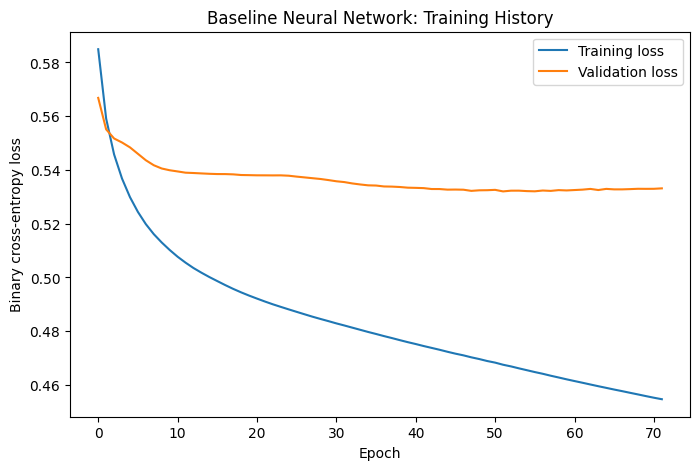

In [27]:
# plot the training and validation loss 
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("Baseline Neural Network: Training History")
plt.legend()
plt.show()

### Training behavior

The neural network completed 44 epochs before early stopping was triggered.
The lowest validation loss occurred at epoch 24, with a value of approximately
0.541.

After this point, the training loss continued to decrease, while the
validation loss remained approximately flat and then increased slightly.
This indicates mild overfitting: the network continued to fit the training
data without corresponding improvement on the validation data.

The use of early stopping with `restore_best_weights=True` ensures that the
model retains the parameters from the best validation epoch rather than
those from the final training epoch.

## 5.4 Validation Performance

We first evaluate the trained neural network on the validation set. As with
the other Stage-0 models, performance is evaluated using multiple
classification metrics rather than accuracy alone.

Because the neural network produces probabilities through its sigmoid output,
we retain the predicted probabilities for subsequent threshold analysis.

In [28]:
from src.evaluation import classification_metrics

validation_probabilities_nn = baseline_nn.predict(
    X_validation_scaled,
    verbose=0,
).ravel()

validation_predictions_nn = (
    validation_probabilities_nn >= 0.5
).astype(int)

nn_validation_metrics = classification_metrics(
    y_validation,
    validation_predictions_nn,
    validation_probabilities_nn,
)

nn_validation_metrics

{'accuracy': 0.7733598409542743,
 'balanced_accuracy': 0.5608290177255695,
 'precision': 0.7727272727272727,
 'recall': 0.1349206349206349,
 'f1': 0.22972972972972974,
 'roc_auc': 0.7052545155993432,
 'pr_auc': 0.5058453728143294,
 'log_loss': 0.5320199728012085}

## 5.5 Threshold Analysis

The sigmoid output of the neural network represents the estimated
probability of the positive class. The default classification threshold of
0.5 is not necessarily appropriate for this imbalanced problem.

We therefore examine a range of thresholds on the validation set. The
threshold is selected using validation performance only and will be frozen
before evaluating the final model on the test set.

In [29]:
thresholds = np.arange(0.10, 0.51, 0.05)

threshold_results_nn = []

for threshold in thresholds:
    predictions = (
        validation_probabilities_nn >= threshold
    ).astype(int)

    metrics = classification_metrics(
        y_validation,
        predictions,
        validation_probabilities_nn,
    )

    threshold_results_nn.append(
        {
            "threshold": threshold,
            **metrics,
        }
    )

threshold_results_nn = pd.DataFrame(threshold_results_nn)

threshold_results_nn

,threshold,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,log_loss
0,0.10,0.481113,0.587796,0.299703,0.801587,0.436285,0.705255,0.505845,0.53202
1,0.15,0.592445,0.643573,0.352060,0.746032,0.478372,0.705255,0.505845,0.53202
2,0.20,0.669980,0.663593,0.401961,0.650794,0.496970,0.705255,0.505845,0.53202
3,0.25,0.705765,0.666330,0.435294,0.587302,0.500000,0.705255,0.505845,0.53202
4,0.30,0.757455,0.682319,0.515385,0.531746,0.523438,0.705255,0.505845,0.53202
5,0.35,0.775348,0.662551,0.567010,0.436508,0.493274,0.705255,0.505845,0.53202
6,0.40,0.771372,0.614985,0.584615,0.301587,0.397906,0.705255,0.505845,0.53202
7,0.45,0.771372,0.583281,0.634146,0.206349,0.311377,0.705255,0.505845,0.53202
8,0.50,0.773360,0.560829,0.772727,0.134921,0.229730,0.705255,0.505845,0.53202


In [30]:
best_nn_threshold_row = threshold_results_nn.loc[
    threshold_results_nn["f1"].idxmax()
]

best_nn_threshold = best_nn_threshold_row["threshold"]

best_nn_threshold_row

threshold            0.300000
accuracy             0.757455
balanced_accuracy    0.682319
precision            0.515385
recall               0.531746
f1                   0.523438
roc_auc              0.705255
pr_auc               0.505845
log_loss             0.532020
Name: 4, dtype: float64

### Selected threshold

The validation-optimal classification threshold is 0.30, selected
programmatically by maximizing F1 score.

At the default threshold of 0.50, the model has relatively low recall for
the positive class. Lowering the threshold to 0.30 increases recall from
approximately 0.167 to 0.548 and improves F1 from approximately 0.271 to
0.517.

This illustrates the precision--recall trade-off in the Stage-0
classification problem. The threshold is selected using the validation set
and will remain fixed for the final test evaluation.

## 6. Hyperparameter Tuning

The baseline neural network provides a reference point for investigating whether alternative architectures and training configurations improve classification performance.

We tune hyperparameters using the training and validation sets, preserving the chronological split established earlier. The test set remains untouched throughout model selection.

The experiments will proceed in stages:

1. **Architecture:** number of hidden layers and neurons.
2. **Regularization:** weight decay and, if warranted, dropout.
3. **Optimization:** learning rate and batch size.

Each configuration will be trained with early stopping based on validation loss. We will record the validation metrics for every configuration and select the best configuration programmatically using F1 score as the primary selection criterion.

The selected hyperparameters will be frozen before the final model is refitted on the combined training and validation data.

### 6.1 Architectural Tuning

We investigate how the depth and width of a feedforward neural network affect its ability to predict the Stage-0 target.

We compare several architectures, ranging from a single hidden layer to three hidden layers. The baseline architecture, `(32, 16)`, is included as a reference.

All configurations use the same training and validation sets, AdamW optimizer, learning rate, weight decay, batch size, and early-stopping criteria. This isolates the effect of architecture as much as possible.

We use F1 score at a fixed classification threshold of 0.30 as the primary selection metric for this experiment. ROC-AUC and PR-AUC are also recorded to assess the models' probability-ranking performance.

The test set is not used during architectural tuning.

In [31]:
hidden_layer_configs = [
    (16,),
    (32,),
    (64,),
    (32, 16),       # Baseline architecture
    (64, 32),
    (64, 32, 16),
]

hidden_layer_configs

[(16,), (32,), (64,), (32, 16), (64, 32), (64, 32, 16)]

In [32]:
NN_TUNING_PARAMS = {
    "learning_rate": 0.001,
    "weight_decay": 0.0,
    "batch_size": 256,
    "epochs": 200,
    "patience": 20,
}

NN_TUNING_THRESHOLD = 0.30

In [34]:
import tensorflow as tf 

architecture_results = []
architecture_models = {}

for i, hidden_layers in enumerate(hidden_layer_configs):

    print(f"Training architecture {hidden_layers}...")

    # Reset the Keras state and random seed for reproducibility.
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    # Build a fresh model.
    model = build_nn_classifier(
        n_features=X_train_scaled.shape[1],
        hidden_layers=hidden_layers,
        activation="relu",
        learning_rate=NN_TUNING_PARAMS["learning_rate"],
        weight_decay=NN_TUNING_PARAMS["weight_decay"],
    )

    # Train with early stopping.
    history = train_nn_classifier(
        model,
        X_train_scaled,
        y_train,
        X_validation_scaled,
        y_validation,
        epochs=NN_TUNING_PARAMS["epochs"],
        batch_size=NN_TUNING_PARAMS["batch_size"],
        patience=NN_TUNING_PARAMS["patience"],
        verbose=0,
    )

    # Predict validation probabilities.
    probabilities = model.predict(
        X_validation_scaled,
        verbose=0,
    ).ravel()

    # Apply the fixed threshold.
    predictions = (
        probabilities >= NN_TUNING_THRESHOLD
    ).astype(int)

    # Evaluate validation performance.
    metrics = classification_metrics(
        y_validation,
        predictions,
        probabilities,
    )

    best_epoch = (
        np.argmin(history.history["val_loss"]) + 1
    )

    best_val_loss = np.min(
        history.history["val_loss"]
    )

    architecture_results.append({
        "hidden_layers": hidden_layers,
        "n_parameters": model.count_params(),
        "epochs_completed": len(history.history["loss"]),
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        **metrics,
    })

    # Retain models for further investigation.
    architecture_models[hidden_layers] = model

architecture_results = pd.DataFrame(
    architecture_results
)

architecture_results

Training architecture (16,)...
Training architecture (32,)...
Training architecture (64,)...
Training architecture (32, 16)...
Training architecture (64, 32)...
Training architecture (64, 32, 16)...


,hidden_layers,n_parameters,epochs_completed,best_epoch,best_val_loss,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,log_loss
0,"(16,)",465,39,19,0.525262,0.695825,0.657057,0.421965,0.579365,0.488294,0.691845,0.441774,0.525262
1,"(32,)",929,110,90,0.538334,0.741551,0.666425,0.485075,0.515873,0.500000,0.689655,0.492730,0.538334
2,"(64,)",1857,53,33,0.529820,0.731610,0.670361,0.469388,0.547619,0.505495,0.699318,0.492993,0.529820
3,"(32, 16)",1441,53,33,0.547361,0.727634,0.657141,0.460993,0.515873,0.486891,0.684897,0.500595,0.547361
4,"(64, 32)",3905,38,18,0.548653,0.731610,0.667719,0.468966,0.539683,0.501845,0.682561,0.479450,0.548653
5,"(64, 32, 16)",4417,36,16,0.550471,0.733598,0.661120,0.471014,0.515873,0.492424,0.679550,0.482090,0.550471


In [35]:
# select the best architecture 

best_architecture_row = architecture_results.loc[
    architecture_results["f1"].idxmax()
]

best_hidden_layers = best_architecture_row["hidden_layers"]

best_architecture_row

hidden_layers           (64,)
n_parameters             1857
epochs_completed           53
best_epoch                 33
best_val_loss         0.52982
accuracy              0.73161
balanced_accuracy    0.670361
precision            0.469388
recall               0.547619
f1                   0.505495
roc_auc              0.699318
pr_auc               0.492993
log_loss              0.52982
Name: 2, dtype: object

### 6.2 Regularization Tuning

We now investigate whether regularization improves the generalization performance of the selected architecture.

We begin with weight decay, which penalizes large model weights during optimization. The architecture and other training parameters are held fixed so that we can isolate the effect of weight decay.

Each configuration is trained with early stopping, and validation performance is evaluated using the same classification threshold of 0.30. The test set remains untouched.

#### 6.2.1: Weight decay

In [36]:
weight_decay_values = [
    0.0,
    1e-5,
    1e-4,
    1e-3,
]

weight_decay_values

[0.0, 1e-05, 0.0001, 0.001]

In [37]:
weight_decay_results = []
weight_decay_models = {}

for weight_decay in weight_decay_values:

    print(f"Training with weight_decay={weight_decay}...")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = build_nn_classifier(
        n_features=X_train_scaled.shape[1],
        hidden_layers=best_hidden_layers,
        activation="relu",
        learning_rate=NN_TUNING_PARAMS["learning_rate"],
        weight_decay=weight_decay,
    )

    history = train_nn_classifier(
        model,
        X_train_scaled,
        y_train,
        X_validation_scaled,
        y_validation,
        epochs=NN_TUNING_PARAMS["epochs"],
        batch_size=NN_TUNING_PARAMS["batch_size"],
        patience=NN_TUNING_PARAMS["patience"],
        verbose=0,
    )

    probabilities = model.predict(
        X_validation_scaled,
        verbose=0,
    ).ravel()

    predictions = (
        probabilities >= NN_TUNING_THRESHOLD
    ).astype(int)

    metrics = classification_metrics(
        y_validation,
        predictions,
        probabilities,
    )

    weight_decay_results.append({
        "weight_decay": weight_decay,
        "epochs_completed": len(history.history["loss"]),
        "best_epoch": np.argmin(
            history.history["val_loss"]
        ) + 1,
        "best_val_loss": np.min(
            history.history["val_loss"]
        ),
        **metrics,
    })

    weight_decay_models[weight_decay] = model

weight_decay_results = pd.DataFrame(
    weight_decay_results
)

weight_decay_results

Training with weight_decay=0.0...
Training with weight_decay=1e-05...
Training with weight_decay=0.0001...
Training with weight_decay=0.001...


,weight_decay,epochs_completed,best_epoch,best_val_loss,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,log_loss
0,0.00000,53,33,0.529820,0.73161,0.670361,0.469388,0.547619,0.505495,0.699318,0.492993,0.529820
1,0.00001,53,33,0.529820,0.73161,0.670361,0.469388,0.547619,0.505495,0.699318,0.492993,0.529820
2,0.00010,53,33,0.529821,0.73161,0.670361,0.469388,0.547619,0.505495,0.699339,0.493175,0.529821
3,0.00100,53,33,0.529819,0.73161,0.670361,0.469388,0.547619,0.505495,0.699360,0.493016,0.529819


In [38]:
# get the best weight decay value:
best_weight_decay_row = weight_decay_results.loc[
    weight_decay_results["f1"].idxmax()
]

best_weight_decay = best_weight_decay_row["weight_decay"]

best_weight_decay_row

weight_decay          0.000000
epochs_completed     53.000000
best_epoch           33.000000
best_val_loss         0.529820
accuracy              0.731610
balanced_accuracy     0.670361
precision             0.469388
recall                0.547619
f1                    0.505495
roc_auc               0.699318
pr_auc                0.492993
log_loss              0.529820
Name: 0, dtype: float64

### 6.3 Learning-Rate Tuning

The learning rate controls the size of parameter updates during neural-network training. A learning rate that is too small may lead to slow convergence, while one that is too large may produce unstable optimization or poorer generalization.

We compare four learning rates while keeping the selected architecture, weight decay, batch size, and early-stopping settings fixed. Each configuration is evaluated on the chronological validation set using a classification threshold of 0.30.

The best learning rate is selected programmatically by maximizing validation F1. ROC-AUC, PR-AUC, and validation loss are also recorded. The test set remains untouched.

In [42]:
learning_rates = [
    0.0003,
    0.0001,
    0.003,
    0.001,
    0.03,
    0.01,
]

learning_rates

[0.0003, 0.0001, 0.003, 0.001, 0.03, 0.01]

In [43]:
learning_rate_results = []
learning_rate_models = {}

for learning_rate in learning_rates:

    print(f"Training with learning_rate={learning_rate}...")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = build_nn_classifier(
        n_features=X_train_scaled.shape[1],
        hidden_layers=best_hidden_layers,
        activation="relu",
        learning_rate=learning_rate,
        weight_decay=best_weight_decay,
    )

    history = train_nn_classifier(
        model,
        X_train_scaled,
        y_train,
        X_validation_scaled,
        y_validation,
        epochs=NN_TUNING_PARAMS["epochs"],
        batch_size=NN_TUNING_PARAMS["batch_size"],
        patience=NN_TUNING_PARAMS["patience"],
        verbose=0,
    )

    probabilities = model.predict(
        X_validation_scaled,
        verbose=0,
    ).ravel()

    predictions = (
        probabilities >= NN_TUNING_THRESHOLD
    ).astype(int)

    metrics = classification_metrics(
        y_validation,
        predictions,
        probabilities,
    )

    learning_rate_results.append({
        "learning_rate": learning_rate,
        "epochs_completed": len(history.history["loss"]),
        "best_epoch": np.argmin(
            history.history["val_loss"]
        ) + 1,
        "best_val_loss": np.min(
            history.history["val_loss"]
        ),
        **metrics,
    })

    learning_rate_models[learning_rate] = model

learning_rate_results = pd.DataFrame(
    learning_rate_results
)

learning_rate_results

Training with learning_rate=0.0003...
Training with learning_rate=0.0001...
Training with learning_rate=0.003...
Training with learning_rate=0.001...
Training with learning_rate=0.03...
Training with learning_rate=0.01...


,learning_rate,epochs_completed,best_epoch,best_val_loss,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,log_loss
0,0.0003,51,31,0.526916,0.693837,0.655730,0.419540,0.579365,0.486667,0.676350,0.439171,0.526916
1,0.0001,113,93,0.526443,0.689861,0.653078,0.414773,0.579365,0.483444,0.677171,0.438585,0.526443
2,0.0030,32,12,0.532428,0.739563,0.675666,0.482517,0.547619,0.513011,0.698771,0.494748,0.532428
3,0.0010,53,33,0.529820,0.731610,0.670361,0.469388,0.547619,0.505495,0.699318,0.492993,0.529820
4,0.0300,43,23,0.522253,0.699801,0.670277,0.430168,0.611111,0.504918,0.710981,0.497968,0.522253
5,0.0100,27,7,0.536692,0.715706,0.662393,0.445860,0.555556,0.494700,0.694644,0.489419,0.536692


In [44]:
best_learning_rate_row = learning_rate_results.loc[
    learning_rate_results["f1"].idxmax()
]

best_learning_rate = best_learning_rate_row["learning_rate"]

best_learning_rate_row

learning_rate         0.003000
epochs_completed     32.000000
best_epoch           12.000000
best_val_loss         0.532428
accuracy              0.739563
balanced_accuracy     0.675666
precision             0.482517
recall                0.547619
f1                    0.513011
roc_auc               0.698771
pr_auc                0.494748
log_loss              0.532428
Name: 2, dtype: float64

#### Learning-rate comparison

We plot validation F1 against the learning rate to examine how the optimization step size affects classification performance. Because learning rates span several orders of magnitude, the horizontal axis uses a logarithmic scale.

The selected learning rate is the one with the highest validation F1 among the tested configurations.

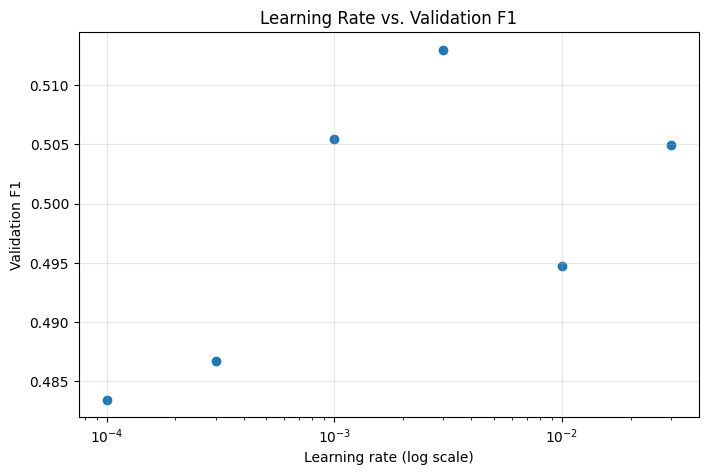

In [47]:
plt.figure(figsize=(8, 5))

plt.scatter(
    learning_rate_results["learning_rate"],
    learning_rate_results["f1"],
)

plt.xscale("log")
plt.xlabel("Learning rate (log scale)")
plt.ylabel("Validation F1")
plt.title("Learning Rate vs. Validation F1")
plt.grid(True, alpha=0.3)
plt.show()

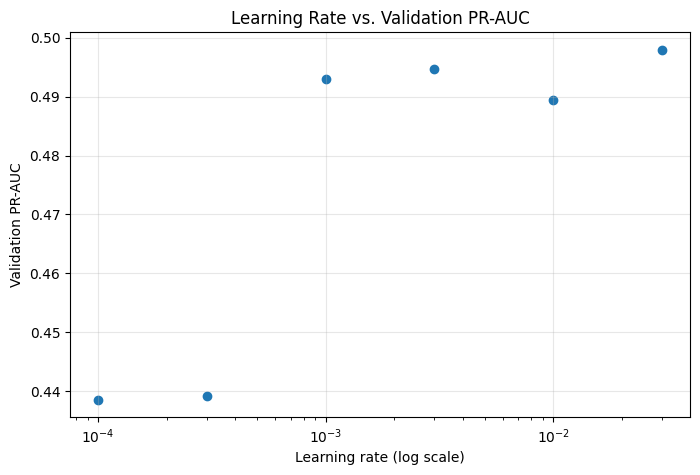

In [48]:
plt.figure(figsize=(8, 5))

plt.scatter(
    learning_rate_results["learning_rate"],
    learning_rate_results["pr_auc"],
)

plt.xscale("log")
plt.xlabel("Learning rate (log scale)")
plt.ylabel("Validation PR-AUC")
plt.title("Learning Rate vs. Validation PR-AUC")
plt.grid(True, alpha=0.3)
plt.show()

### 6.4 Batch-Size Tuning

Batch size determines the number of training observations used to compute each gradient update. Smaller batches produce more frequent, noisier updates, whereas larger batches produce less frequent updates based on more observations.

We investigate the effect of batch size on validation performance while keeping the selected architecture, learning rate, weight decay, and early-stopping procedure fixed.

The configurations are evaluated using validation F1 at the fixed classification threshold of 0.30. We also record PR-AUC, ROC-AUC, and validation loss. The test set remains untouched.

In [52]:
batch_sizes = [32, 64, 128, 256, 512, 768, 1024]

batch_sizes

[32, 64, 128, 256, 512, 768, 1024]

In [53]:
batch_size_results = []
batch_size_models = {}

for batch_size in batch_sizes:

    print(f"Training with batch_size={batch_size}...")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = build_nn_classifier(
        n_features=X_train_scaled.shape[1],
        hidden_layers=best_hidden_layers,
        activation="relu",
        learning_rate=best_learning_rate,
        weight_decay=best_weight_decay,
    )

    history = train_nn_classifier(
        model,
        X_train_scaled,
        y_train,
        X_validation_scaled,
        y_validation,
        epochs=NN_TUNING_PARAMS["epochs"],
        batch_size=batch_size,
        patience=NN_TUNING_PARAMS["patience"],
        verbose=0,
    )

    probabilities = model.predict(
        X_validation_scaled,
        verbose=0,
    ).ravel()

    predictions = (
        probabilities >= NN_TUNING_THRESHOLD
    ).astype(int)

    metrics = classification_metrics(
        y_validation,
        predictions,
        probabilities,
    )

    batch_size_results.append({
        "batch_size": batch_size,
        "epochs_completed": len(history.history["loss"]),
        "best_epoch": np.argmin(
            history.history["val_loss"]
        ) + 1,
        "best_val_loss": np.min(
            history.history["val_loss"]
        ),
        **metrics,
    })

    batch_size_models[batch_size] = model

batch_size_results = pd.DataFrame(
    batch_size_results
)

batch_size_results

Training with batch_size=32...
Training with batch_size=64...
Training with batch_size=128...
Training with batch_size=256...
Training with batch_size=512...
Training with batch_size=768...
Training with batch_size=1024...


,batch_size,epochs_completed,best_epoch,best_val_loss,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,log_loss
0,32,24,4,0.522358,0.729622,0.658467,0.464286,0.515873,0.488722,0.707675,0.485440,0.522358
1,64,23,3,0.533953,0.743539,0.657183,0.488000,0.484127,0.486056,0.693971,0.475929,0.533953
2,128,34,14,0.533298,0.751491,0.657204,0.504274,0.468254,0.485597,0.703107,0.503393,0.533298
3,256,32,12,0.532428,0.739563,0.675666,0.482517,0.547619,0.513011,0.698771,0.494748,0.532428
4,512,44,24,0.532644,0.745527,0.677003,0.492754,0.539683,0.515152,0.704497,0.508431,0.532644
5,768,39,19,0.533554,0.739563,0.686234,0.483444,0.579365,0.527076,0.695529,0.483556,0.533554
6,1024,44,24,0.531607,0.737575,0.687550,0.480519,0.587302,0.528571,0.697718,0.485912,0.531607


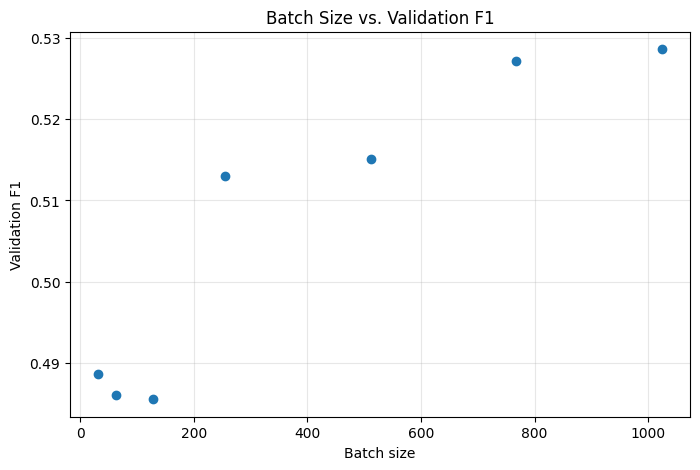

In [57]:
plt.figure(figsize=(8, 5))

plt.scatter(
    batch_size_results["batch_size"],
    batch_size_results["f1"],
)

plt.xlabel("Batch size")
plt.ylabel("Validation F1")
plt.title("Batch Size vs. Validation F1")
plt.grid(True, alpha=0.3)
plt.show()

In [59]:
best_batch_size_row = batch_size_results.loc[
    batch_size_results["f1"].idxmax()
]

best_batch_size = int(
    best_batch_size_row["batch_size"]
)

best_batch_size_row

batch_size           1024.000000
epochs_completed       44.000000
best_epoch             24.000000
best_val_loss           0.531607
accuracy                0.737575
balanced_accuracy       0.687550
precision               0.480519
recall                  0.587302
f1                      0.528571
roc_auc                 0.697718
pr_auc                  0.485912
log_loss                0.531607
Name: 6, dtype: float64

## 7. Train Using Selected Configuration

In [61]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

selected_nn = build_nn_classifier(
    n_features=X_train_scaled.shape[1],
    hidden_layers=best_hidden_layers,
    activation="relu",
    learning_rate=best_learning_rate,
    weight_decay=best_weight_decay,
)

selected_nn_history = train_nn_classifier(
    selected_nn,
    X_train_scaled,
    y_train,
    X_validation_scaled,
    y_validation,
    epochs=NN_TUNING_PARAMS["epochs"],
    batch_size=best_batch_size,
    patience=NN_TUNING_PARAMS["patience"],
    verbose=1,
)

Epoch 1/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.4168 - loss: 0.7628 - val_accuracy: 0.6123 - val_loss: 0.6624
Epoch 2/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6168 - loss: 0.6555 - val_accuracy: 0.7137 - val_loss: 0.5932
Epoch 3/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7143 - loss: 0.5980 - val_accuracy: 0.7535 - val_loss: 0.5606
Epoch 4/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7383 - loss: 0.5659 - val_accuracy: 0.7654 - val_loss: 0.5474
Epoch 5/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7460 - loss: 0.5487 - val_accuracy: 0.7654 - val_loss: 0.5437
Epoch 6/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7490 - loss: 0.5388 - val_accuracy: 0.7614 - val_loss: 0.5441
Epoch 7/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7494 - loss: 0.5312 - val_accuracy: 0.7614 - val_loss: 0.5457
Epoch 8/200
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7497 - loss: 0.5244 - val_accuracy: 0.7614 - val_loss: 0.547

### 7.1 Validation Probabilities

The selected neural network produces probabilities for the positive class through its sigmoid output. We use these validation probabilities to determine a classification threshold.

The test set remains untouched during threshold selection.

In [62]:
selected_nn_val_probabilities = selected_nn.predict(
    X_validation_scaled,
    verbose=0,
).ravel()

### 7.2 Threshold Selection

We evaluate classification thresholds between 0.10 and 0.50 on the validation set. The selected threshold maximizes validation F1, while ROC-AUC and PR-AUC provide complementary measures of probability-ranking performance.

The threshold is selected programmatically and will be fixed before the final test evaluation.

In [63]:
threshold_results_nn = []

for threshold in np.arange(0.10, 0.51, 0.025):
    predictions = (
        selected_nn_val_probabilities >= threshold
    ).astype(int)

    metrics = classification_metrics(
        y_validation,
        predictions,
        selected_nn_val_probabilities,
    )

    threshold_results_nn.append({
        "threshold": threshold,
        **metrics,
    })

threshold_results_nn = pd.DataFrame(
    threshold_results_nn
)

threshold_results_nn

,threshold,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,log_loss
0,0.100,0.463221,0.573218,0.290698,0.793651,0.425532,0.697718,0.485912,0.531607
1,0.125,0.522863,0.605080,0.314935,0.769841,0.447005,0.697718,0.485912,0.531607
2,0.150,0.570577,0.621058,0.334559,0.722222,0.457286,0.697718,0.485912,0.531607
3,0.175,0.604374,0.625111,0.348548,0.666667,0.457766,0.697718,0.485912,0.531607
4,0.200,0.640159,0.646341,0.375566,0.658730,0.478386,0.697718,0.485912,0.531607
5,0.225,0.664016,0.654330,0.394089,0.634921,0.486322,0.697718,0.485912,0.531607
6,0.250,0.683897,0.662309,0.412698,0.619048,0.495238,0.697718,0.485912,0.531607
7,0.275,0.711730,0.675593,0.444444,0.603175,0.511785,0.697718,0.485912,0.531607
8,0.300,0.737575,0.687550,0.480519,0.587302,0.528571,0.697718,0.485912,0.531607
9,0.325,0.741551,0.658499,0.484375,0.492063,0.488189,0.697718,0.485912,0.531607


In [64]:
best_nn_threshold_row = threshold_results_nn.loc[
    threshold_results_nn["f1"].idxmax()
]

best_nn_threshold = float(
    best_nn_threshold_row["threshold"]
)

best_nn_threshold_row

threshold            0.300000
accuracy             0.737575
balanced_accuracy    0.687550
precision            0.480519
recall               0.587302
f1                   0.528571
roc_auc              0.697718
pr_auc               0.485912
log_loss             0.531607
Name: 8, dtype: float64

### 7.3: Final Test Evaluation

We evaluate the selected neural network on the chronological test set covering 2023–2026. The architecture, training hyperparameters, and classification threshold were selected using the training and validation data.

We do not use the test results to make further model-selection decisions. This evaluation provides an estimate of performance on a later, unseen market period.

In [65]:
test_probabilities_nn = selected_nn.predict(
    X_test_scaled,
    verbose=0,
).ravel()

test_predictions_nn = (
    test_probabilities_nn >= best_nn_threshold
).astype(int)

nn_test_metrics = classification_metrics(
    y_test,
    test_predictions_nn,
    test_probabilities_nn,
)

nn_test_metrics

{'accuracy': 0.6605005440696409,
 'balanced_accuracy': 0.6673200490939282,
 'precision': 0.3394736842105263,
 'recall': 0.6789473684210526,
 'f1': 0.45263157894736844,
 'roc_auc': 0.7248935094938993,
 'pr_auc': 0.38129350046275395,
 'log_loss': 0.46749812364578247}

In [66]:
from sklearn.metrics import confusion_matrix

nn_test_confusion_matrix = confusion_matrix(
    y_test,
    test_predictions_nn,
)

nn_test_confusion_matrix

array([[478, 251],
       [ 61, 129]])

## 8. Save Model

### 8.1: Save the selected model

In [67]:
from pathlib import Path
import joblib
import json

PROJECT_ROOT = Path.cwd().parent
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Save the trained neural network.
nn_model_path = MODELS_DIR / "stage0_neural_network.keras"
selected_nn.save(nn_model_path)

# Save the scaler used to transform the model inputs.
nn_scaler_path = MODELS_DIR / "stage0_neural_network_scaler.joblib"
joblib.dump(scaler, nn_scaler_path)

print(f"Model saved to: {nn_model_path}")
print(f"Scaler saved to: {nn_scaler_path}")

Model saved to: /Users/amitkumar/Desktop/Computing/Projects/Finance/market-volatility/models/stage0_neural_network.keras
Scaler saved to: /Users/amitkumar/Desktop/Computing/Projects/Finance/market-volatility/models/stage0_neural_network_scaler.joblib


### 8.2: Save the selected configuration

In [68]:
nn_config = {
    "hidden_layers": list(best_hidden_layers),
    "learning_rate": float(best_learning_rate),
    "weight_decay": float(best_weight_decay),
    "batch_size": int(best_batch_size),
    "classification_threshold": float(best_nn_threshold),
    "target_threshold": 0.2,
    "target_window": 5,
}

nn_config_path = MODELS_DIR / "stage0_neural_network_config.json"

with open(nn_config_path, "w") as file:
    json.dump(nn_config, file, indent=4)

nn_config

{'hidden_layers': [64],
 'learning_rate': 0.003,
 'weight_decay': 0.0,
 'batch_size': 1024,
 'classification_threshold': 0.29999999999999993,
 'target_threshold': 0.2,
 'target_window': 5}

### 8.3: Verify the saved artifacts

In [69]:
assert nn_model_path.exists()
assert nn_scaler_path.exists()
assert nn_config_path.exists()

print("All neural-network artifacts saved successfully.")

All neural-network artifacts saved successfully.
